### **Student Information**
GitHub ID: 0-Gixty-0

Kaggle name: Erik Andreasson

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

The preprocessing applied in my submission consists of the following steps run in order:

1. Load raw texts.
2. Remove exact duplicates.
3. Clean the text using a function which applies specific rules.
4. Tokenize using TweetTokenizer from NLTK.
5. Collapse repeated sequences.
6. Create a stratified 80/20 split for training and validation sets.

#### 1.1.1 Data Loading
The downloaded Kaggle competition data is joined into a single dataframe for all posts with the `post_id`, `text`, `set`, and `label` features included. The dataframe is split into separate training and test dataframes verified to contain the correct number of posts (3,360 train and 1,440 test).

#### 1.1.2 Check Missing Values & Duplicates
There are no missing values for the training set and the only missing values for the test set are those of the emotion label, which is expected. Therefore, no imputation is needed.

However, the dataset contains 50 duplicate texts in training and 8 duplicates in test. Among the training duplicates, 34 have the same emotion label and 16 have different labels. This suggests that the duplicates may originate from combining multiple datasets annotated slightly differently. This is expected as the Kaggle overview states the dataset is assembled from multiple sources. 

The 34 posts that are genuine duplicates in the training set are removed while the 16 ambiguous duplicates are retained. While it can be argued that these could be removed as well since the 16 duplicates and their originals (32 rows) only constitute 32/3360 ≃ 1% of the dataset, their information is genuinely useful. The fact that a post is included multiple times under different labels suggests that the text contains multiple emotions or different degrees of multiple emotions. Therefore, including them preserves the noise to be expected of the test set and discourages the model from becoming overly confident on a single emotion for ambiguous texts.

There are 59 posts in the test set that have the exact same text as in training. This attribute of the dataset split is not exploited by using hardcoded answers since that doesn't meaningfully add to modelling emotion classification. However, it does make all test scores slightly more optimistic for everyone.

#### 1.1.3 Exploration of Contents

The posts in the provided dataset contain many instances of structured patterns which occurred when the dataset was constructed. The patterns include but are not limited to anonymized names and usernames, URL placeholders, and markup syntax. Furthermore, the posts contain elements common to social media language like emojis and emoticons which require special handling in preprocessing. The contents of the test set are never used to make decisions and were only checked for duplicates and overlap.

**Check 1: Character counts.** The first check of the contents displays the 40 most common characters, which reveal some important properties of the textual content. Punctuation markers like ".", ",", "'", "!", and "?" dominate the top of the ranking, as expected from the English language. However, some characters appear to be disproportionately represented for text sourced from social media. For example, the inclusion of "[" and "]" at places 7 and 6 respectively, with almost identical counts, points to a structural mechanism of the dataset rather than social media posting. Similar conclusions can be drawn for the characters ":", "<", ">", and "*", which are not that common in everyday language but are often used in markup languages. Furthermore, the characters "#" and "@" are commonplace in our data, which is expected from social media as they are common functional characters with hashtags serving as prefixes to topics and the at sign (@) as the prefix to usernames. In summary, these findings suggest the posts contain many structured placeholders and patterns.

**Check 2: Word patterns.** To test this, uncommon structures, meaning words that do not only contain letters, digits, and standard punctuation, are extracted from the text. These uncommon structures are then collapsed by converting any sequence of digits to the number 9, any sequence of uppercase letters to "A", and any sequence of lowercase letters to "a". This produces our list of commonly occurring "words" that do not match standard language structure. The list confirms our hypothesis of structured text with square bracket structures containing only uppercase letters occurring 201 times (251 counting those with punctuation at the end), at signs (@) followed by angle brackets containing only lowercase letters occurring 172 times, and suspicious structures of uppercase letters surrounded by hashtags.

**Check 3: Exact forms.** The exact strings for the most common patterns are extracted using regex rules. The results confirm the contents of the identified structures in the text with anonymized names (square brackets) and usernames (at sign with angle brackets) being the two most dominant structures. This clearly shows that the structures we found are a result of how the dataset was constructed. Furthermore, we find that the suspicious hashtag structure from earlier is actually a structure for parsed URLs in the construction of the dataset. Since there are multiple variants of this structure with varying numbers of hashtags, a regex rule matching any number of hashtags is used to identify all variants.

Emojis are also common, with the "face with tears of joy" emoji '😂' occurring 62 times across the posts. It is important that our preprocessing retains these emojis as input to our model since an emoji intrinsically contains a clear statement about emotion.

Each structure identified by exploration of the contents justifies its own cleaning rule (section 1.1.4) which is required in order to make tokenization meaningful for emotion classification. In nearly all cases, the rules are designed to extract the meaningful word, phrase, or placeholder token from the unnecessary structural characters. 

#### 1.1.4 Data Cleaning & Standardizing

The findings from the previous section illustrate the requirement for special cleaning and tokenizing before feeding to a classification model. A naive tokenizer would take structures like "[NAME]" and split it into "[", "NAME", "]" which is incorrect as the word should only represent one token which indicates that a name is used in the post. Similarly, markup-style words with bold and strikethrough symbols would split incorrectly so the styling is dropped in favor of keeping the word. 

To solve these kinds of problems, the preprocessing runs a cleaning function on the raw text which applies the following rules in order before tokenization:

| # | Rule | Example (before -> after) | Why |
|--:|------|--------------------------|-----|
| 1 | Decode HTML entities | `&amp;` -> `&`, `&gt;` -> `>` | Later rules then see the real characters |
| 2 | Remove invisible emoji modifiers | `❤️` -> `❤` | Variants of the same emoji become one token |
| 3 | Strip HTML tags (except `<username>`) | `<i>wow</i>` -> `wow` | Tags are formatting, not content |
| 4 | Mentions -> placeholder | `@<username>`, `@bob` -> `USERTOKEN` | One token for referencing a user |
| 5 | URLs -> placeholder | `##URL###`, `https://…`, `www.…` -> `URLTOKEN` | Covers all `#` variants found in 1.1.3 and real links |
| 6 | Anonymized names -> placeholder | `[NAME]` -> `NAMETOKEN` | Stops the tokenizer splitting it into `[`, `NAME`, `]` |
| 7 | Anonymized religions -> placeholder | `[RELIGION]` -> `RELIGIONTOKEN` | Same as above |
| 8 | Subreddit/user links -> placeholder | `r/funny`, `u/bob` -> `REDDITTOKEN` | Prevents incorrect splitting and Reddit links carry no emotion themselves |
| 9 | Drop quote marker at the start of a post | `> quoted text` -> `quoted text` | Keep the words, drop the markup |
| 10 | Strikethrough -> keep words | `~~text~~` -> `text` | Keep the words, drop the markup |
| 11 | Bold/action markup -> keep words | `*sigh*`, `**bold**` -> `sigh`, `bold` | Keep the words, drop the markup |
| 12 | Music notes -> placeholder | `♪♪` -> `MUSICTOKEN` | Marks lyrics or singing |
| 13 | Hashtags -> keep word | `#blessed` -> `blessed` | The topic word is the content. Runs after rule 5 so `##URL##` is not damaged |
| 14 | Curly -> straight quotes | `don’t` -> `don't` | Both spellings become the same token |
| 15 | Collapse whitespace | `a␣␣␣b` -> `a b` | Tidy output for the tokenizer |

Another important point in cleaning of text data is the removal of stopwords. In some cases, like topic analysis, there is no need for stopwords, so they are removed entirely. I considered also removing them from this data; however, many stopwords convey emotion and can also functionally negate emotions. For instance, "happy" and "not happy" are opposing emotions differing only in a stopword. The sentence-embedding transformer used in this implementation (mpnet) exploits this connection and inverse document frequency already downweights common words. Therefore, I chose to keep the stopwords in.

Finally, tokenization is applied to the cleaned text using the _TweetTokenizer_ provided by NLTK which has many desirable properties for tokenization on social media text. The most important properties for our data are that it lowercases all text besides emoticons like _:D_, reduces the length of identical character sequences to exactly three so that "sooooo" and "sooooooo" map to the same token "sooo", retains contractions and emoticon structures as one token, and keeps emojis as well as repeated punctuation as separate tokens. All of the mentioned properties are particularly important for emotion classification as they all retain emotional information like repeated exclamation points, laughing emojis, emoticons displaying emotions, and emotively extended words. A naive tokenizer would have split this crucial emotional information.

Note that the pretrained emotion classifier transformer models (j-hartmann and SamLowe, frozen and fine-tuned) used in this implementation receive the raw text with only HTML and whitespace rules applied. This keeps the input similar to what the models were pretrained on. However, it also comes with the limitation that the loop collapse is not applied, which may affect the results. Nevertheless, the number of looped texts is low in comparison to the full training set so the effect is likely minimal.

#### 1.1.5 Class Distribution & Token Counts

The class distribution in the table and figure below shows that the difference in counts between the largest class _joy_ and the smallest class _fear_ is 588, making _joy_ more than 3 times larger. The overall observation is that the split between labels is very unequal with the smallest class only 8.48% of the dataset, two other labels having about half as many posts as _joy_, and a further two having about three quarters as many. These observations clearly indicate the necessity of using class balancing of weights in trained models and making training and validation splits with stratified sampling. Without them, the model could ignore fear without a large loss in accuracy, which macro F1 detects by giving a low score.

| Emotion  | Count | % of dataset | Ratio to joy |
|----------|------:|-------------:|-------------:|
| joy      |   870 |       26.16% |         1.00 |
| anger    |   667 |       20.05% |         0.77 |
| sadness  |   619 |       18.61% |         0.71 |
| disgust  |   451 |       13.56% |         0.52 |
| surprise |   437 |       13.14% |         0.50 |
| fear     |   282 |        8.48% |         0.32 |
| **Total**| **3326** |  **100%** |              |

![Training dataset class distribution](plots/1_preprocessing/class_distribution_train.png)

The summary statistics in the table below show that the first, second, and third quartiles are all respectively consistent across all emotions. Furthermore, the means lie between 15 and 20 tokens, which is above the medians due to the long outliers. These results indicate that the majority of the posts in our dataset have a length of around 9–22 tokens regardless of what emotion the document has. These lengths, and minimum values of only one or two tokens, are very typical of social media posts. However, the excessively large maximum values of over 500 tokens for some emotions are especially atypical for text in social media contexts.

| Emotion  | Count | Mean | Std  | Min | 25% | Median | 75% | Max |
|----------|------:|-----:|-----:|----:|----:|-------:|----:|----:|
| anger    |   667 | 20.3 | 36.5 |   2 |   9 |     14 |  22 | 509 |
| disgust  |   451 | 18.7 | 28.9 |   1 |   9 |     14 |  22 | 506 |
| fear     |   282 | 17.1 | 17.5 |   3 |   9 |     15 |  21 | 242 |
| joy      |   870 | 20.4 | 36.2 |   2 |   9 |     14 |  21 | 508 |
| sadness  |   619 | 18.2 | 20.6 |   1 |  10 |     15 |  21 | 387 |
| surprise |   437 | 14.9 |  8.5 |   2 |   9 |     14 |  19 |  79 |

The boxplot below shows that there are many outliers at or above the whiskers for each emotion, which indicates that there are many abnormally long texts as opposed to a few extreme outliers.

![Document token counts boxplot for training data](plots/1_preprocessing/word_count_by_emotion_boxplot.png)

If these outliers contain legitimate content that conveys an emotion, then they may still carry some information which can be used for training a classification model. However, their excessive length is more an indicator of something having gone wrong, such as bot comments or advertisements in social media threads, which could inflate the weight of repeated terms.

#### 1.1.6 Identifying Repetitions

The extreme outliers are almost all repetition loops, with 27 posts having fewer than 30% unique tokens. The condensed results are shown here with the full prints in the implementation section:

| Emotion  | Tokens | Unique | Excerpt (longest post) |
|----------|-------:|-------:|------------------------|
| anger    |    509 |     4% | "…I was in the kitchen, and I was in the kitchen, and I was in the kitchen…" |
| disgust  |    506 |     4% | "…Oh, oh, oh, oh, oh, oh, oh, oh, oh…" |
| fear     |    242 |     3% | "We are the ones who are the ones who are the ones who…" |
| joy      |    508 |     1% | "…baby Bhar about dark dark dark dark dark dark…" |
| sadness  |    387 |     3% | "…the Lord of the Rings, the Lord of the Rings, the Lord of the Rings…" |
| surprise |     79 |    61% | "He did not explain why he started Cao Cao to give security…" (no loop) |

From the results we observe that the majority of the longest posts have less than 5% unique tokens and consist completely of looped text repeating over and over. Most do not appear to be written by a real person, though the second longest for sadness with 158 tokens "USERTOKEN USERTOKEN USERTOKEN please please please please please please please please please please please..." may be written by an actual person since it begins with three user tokens, likely referencing those users directly rather than a generic botted comment. Interestingly, surprise had the shortest maximum length and doesn't contain loops in its top 3. In either case, the repeated texts are not useful to the model as the large number of nonsensically repeated tokens inflates the term frequency which scales down the importance of words within a post that could aid in classification. Furthermore, the pretrained sentence-embedding model (mpnet) is also affected, as its embedding is pulled towards the repeated phrase instead of reflecting the meaning of the text.

To remove the repeated content, this section of the code applies a function `collapse_repeats` which takes a list of tokens and transforms repeated sequences with each pattern having a maximum length of 10 tokens into at most two copies of the sequence which preserves emphasis for genuine repeats. Applying this to our test and training data brought the number of loop posts in the training data down to 11 with the longest post in training now at 153 tokens.

#### 1.1.7 Final Training & Validation Split

Because of the large class imbalance shown in section 1.1.5, a stratified split is used to ensure that the distribution of the emotion labels is the same in both splits as in the full training set. An unstratified split is used as a baseline for comparison with the stratified one. Both splits use an 80/20 split for training and validation respectively with the seed set to 42.

### 1.2 Feature Engineering Steps

[Content for Feature Engineering]

### 1.3 Explanation of Your Model

[Content for Model Explanation]

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

[Content for AI Prompts and your reason]

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

### 1.1 Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import html
import re
import collections
import os
import nltk
nltk.download("stopwords")
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split

LABELS = ["joy", "anger", "sadness", "disgust", "surprise", "fear"]
SEED = 42

# Every plot is also saved as plots/<section>/<name>.png, one folder per notebook section
PLOT_DIR = "plots"
def save_plot(fig, section, name):
    """Save a figure to plots/<section>/<name>.png, creating the folder if needed."""
    folder = os.path.join(PLOT_DIR, section)
    os.makedirs(folder, exist_ok=True)
    fig.savefig(os.path.join(folder, f"{name}.png"), dpi=150, bbox_inches="tight")

[nltk_data] Downloading package stopwords to /home/enarde/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### 1.2 Data Loading

In [2]:
### Add the code related to the preprocessing steps in cells inside this section
DATA_DIR = "data/kaggle"

# Load the raw files
posts = pd.read_json(f"{DATA_DIR}/final_posts.json")
split = pd.read_csv(f"{DATA_DIR}/data_identification.csv")
labels = pd.read_csv(f"{DATA_DIR}/emotion.csv")

# Join on post_id
df = posts.merge(split, on="post_id").merge(labels, on="post_id", how="left")

train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df = df[df["set"] == "test"].reset_index(drop=True)

print(train_df.shape, test_df.shape) # (3360, 4) (1440, 4)
print(train_df["label"].value_counts())
train_df.head()

(3360, 4) (1440, 4)
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64


,post_id,text,set,label
0,f8bv5zh,Thought it looked weird as well.,train,disgust
1,q0rr1l9,Bear died in a pit,train,disgust
2,p94rwgk,I have endured worse.,train,sadness
3,9u6wtvm,The pottery around Brasov is in danger,train,fear
4,h8ea329,"Meanwhile, our soldiers were approaching the a...",train,fear


### 1.3 Check Missing Values & Duplicates

In [3]:
# Missing labels for test data is expected
for name, d in {"train": train_df, "test": test_df}.items():
    print(f"--- {name} ---")
    print("shape:", d.shape)
    print("missing values per column:")
    print(d.isna().sum())
    print()

--- train ---
shape: (3360, 4)
missing values per column:
post_id    0
text       0
set        0
label      0
dtype: int64

--- test ---
shape: (1440, 4)
missing values per column:
post_id       0
text          0
set           0
label      1440
dtype: int64



In [4]:
for name, d in {"train": train_df, "test": test_df}.items():
    print(f"--- {name} ---")
    print("Column data types:")
    print(d.dtypes)
    print()
    print("Duplicate ids:")
    print(d["post_id"].duplicated().sum())
    print("Duplicate texts:")
    print(d["text"].duplicated().sum())
    print("Duplicate texts with same label:")
    print(d.duplicated(subset=["text", "label"]).sum())
    print()
    print("Unique emotion labels:")
    for emotion in d['label'].unique():
        print(emotion)
    print()

print("Number of texts appearing in both train and test:")
shared = set(train_df["text"]) & set(test_df["text"])
print(len(shared))

--- train ---
Column data types:
post_id    str
text       str
set        str
label      str
dtype: object

Duplicate ids:
0
Duplicate texts:
50
Duplicate texts with same label:
34

Unique emotion labels:
disgust
sadness
fear
joy
anger
surprise

--- test ---
Column data types:
post_id    str
text       str
set        str
label      str
dtype: object

Duplicate ids:
0
Duplicate texts:
8
Duplicate texts with same label:
8

Unique emotion labels:
nan

Number of texts appearing in both train and test:
59


In [5]:
# remove duplicates from training data
train_df = train_df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
print("Duplicate texts with same label (Training):")
print(train_df.duplicated(subset=["text", "label"]).sum())

Duplicate texts with same label (Training):
0


### 1.4 Exploration of Contents

In [6]:
# Check the most common characters used in the texts
chars = collections.Counter(ch for s in train_df.text for ch in s
                            if not ch.isalnum() and not ch.isspace())
chars.most_common(40)

[('.', 3120),
 (',', 2773),
 ("'", 1530),
 ('!', 591),
 ('?', 346),
 (']', 274),
 ('[', 273),
 ('’', 259),
 ('>', 194),
 ('"', 186),
 ('-', 178),
 ('<', 176),
 (':', 175),
 ('@', 175),
 ('#', 133),
 ('*', 83),
 (')', 81),
 ('😂', 62),
 ('(', 53),
 ('/', 53),
 ('😭', 47),
 (';', 30),
 ('️', 29),
 ('”', 20),
 ('“', 19),
 ('%', 13),
 ('♪', 13),
 ('^', 12),
 ('🥰', 11),
 ('🙏', 11),
 ('❤', 10),
 ('😁', 10),
 ('🤣', 10),
 ('~', 8),
 ('👏', 7),
 ('🤔', 7),
 ('$', 6),
 ('+', 5),
 ('♂', 5),
 ('🙄', 4)]

In [7]:
# Identify commonly occurring templates and patterns in the text
def shape(w):
    w = re.sub(r"\d+", "9", w)
    w = re.sub(r"[A-Z]+", "A", w)
    return re.sub(r"[a-z]+", "a", w)

odd = [w for s in train_df.text for w in s.split() if re.search(r"[^\w'.,!?\"’]", w)]
collections.Counter(shape(w) for w in odd).most_common(30)

[('[A]', 201),
 ('@<a>', 172),
 ('Aa:', 67),
 ('a-a', 42),
 ('a:', 33),
 ('-', 32),
 ('[A].', 30),
 ('a;', 23),
 ('[A],', 20),
 ('a/a', 19),
 ('(a', 15),
 ('♪', 13),
 ('##A###', 11),
 ('a)', 11),
 (':)', 11),
 ('*a*', 10),
 (':(', 10),
 ('Aa-Aa', 10),
 ('#a', 10),
 ('>', 9),
 ('a*', 9),
 ('#Aa', 8),
 ('9%', 8),
 ('##A##', 7),
 ('a”', 7),
 ('“a', 6),
 ('a-a,', 6),
 ('a).', 6),
 ('*a', 6),
 ('*Aa', 6)]

In [8]:
# List bracketed or marked words in the texts
collections.Counter(re.findall(r"[\[<{#][\w#]+[\]>}#]*", " ".join(train_df.text))).most_common(20)

[('[NAME]', 270),
 ('<username>', 173),
 ('##URL###', 11),
 ('##URL##', 7),
 ('#RwOT', 3),
 ('<3', 2),
 ('#Famille', 1),
 ('##URL####', 1),
 ('#PLAY', 1),
 ('#CHOGM2022', 1),
 ('#Pizzets', 1),
 ('#Fact', 1),
 ('#1', 1),
 ('[Think]', 1),
 ('#HorrorBaro', 1),
 ('#VfB', 1),
 ('#likeapig', 1),
 ('#Alert', 1),
 ('#blessingswe', 1),
 ('#oromoliberationarmy', 1)]

### 1.5 Data Cleaning & Standardizing

In [9]:
def clean_text(text):
    # Decode HTML entities first (&amp; -> &), so later rules see real characters
    text = html.unescape(text)

    # Remove invisible emoji modifiers, so ❤️ and ❤ become the same token
    text = text.replace("\ufe0f", "").replace("\u200d", "")

    # Strip HTML tags like <li>, <i>, </b>. The (?!username>) part skips
    #    <username>, which is handled in the next rule
    text = re.sub(r"<(?!username>)/?[a-zA-Z]+\s*/?>", " ", text)

    # Placeholders -> consistent tokens
    text = re.sub(r"@<username>|@\w+", " USERTOKEN ", text)
    text = re.sub(r"#*\bURL\b#*|https?://\S+|www\.\S+", " URLTOKEN ", text) # all ##URL### variants
    text = re.sub(r"\[NAME\]", " NAMETOKEN ", text)
    text = re.sub(r"\[RELIGION\]", " RELIGIONTOKEN ", text)
    text = re.sub(r"\b[ru]/\w+", " REDDITTOKEN ", text)

    # Reddit formatting: keep the words, drop the markup
    text = re.sub(r"^\s*>+\s*", "", text)          # quote marker at the start of a post
    text = re.sub(r"~~(.+?)~~", r"\1", text)       # ~~strikethrough~~
    text = re.sub(r"\*+([^*]+?)\*+", r"\1", text)  # *action* and **bold**

    # Music notes mark lyrics or singing
    text = re.sub(r"♪+", " MUSICTOKEN ", text)

    # Hashtags: keep the word, drop the '#'. This runs after the URL rule so ##URL## isn't damaged
    text = re.sub(r"#(\w+)", r"\1", text)

    # Curly quotes -> straight quotes, then collapse whitespace
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", text).strip()

In [10]:
# TweetTokenizer keeps emoji and contractions, and shortens "sooooo" to "sooo"
tok = TweetTokenizer(preserve_case=False, reduce_len=True)

# Keep negations: removing "not" turns "not happy" into "happy"
NEGATIONS = {"no", "not", "nor", "never", "don't", "didn't", "isn't", "wasn't",
             "can't", "won't", "shouldn't", "couldn't", "doesn't", "aren't"}
STOP = set(stopwords.words("english")) - NEGATIONS

def tokenize(text, remove_stop=False):
    toks = tok.tokenize(text)
    if remove_stop:
        toks = [t for t in toks if t not in STOP]
    return toks

train_df["clean_text"] = train_df["text"].map(clean_text)
train_df["tokens"] = train_df["clean_text"].map(tokenize)
test_df["clean_text"] = test_df["text"].map(clean_text)
test_df["tokens"] = test_df["clean_text"].map(tokenize)

In [11]:
# Most common tokenizer outputs
collections.Counter(x for s in train_df.text for x in tokenize(clean_text(s))
                    if not re.fullmatch(r"[A-Za-z']+|[.,!?\"]+", x)).most_common(30)

[(':', 129),
 ('-', 69),
 (')', 64),
 ('😂', 54),
 ('(', 40),
 ('/', 39),
 ('😭', 37),
 (';', 29),
 (':)', 15),
 ('%', 13),
 ('^', 12),
 (':(', 11),
 ('*', 11),
 ('2', 10),
 ('19', 10),
 ('3', 10),
 ('8', 10),
 ('🥰', 10),
 ('❤', 10),
 ('🙏', 10),
 ('🤣', 10),
 ('30', 9),
 ('1', 9),
 ('😁', 9),
 ('100', 7),
 ('10', 7),
 ('👏', 7),
 ('20', 7),
 ('🤔', 7),
 ('4', 6)]

### 1.6 Class Distribution & Token Counts

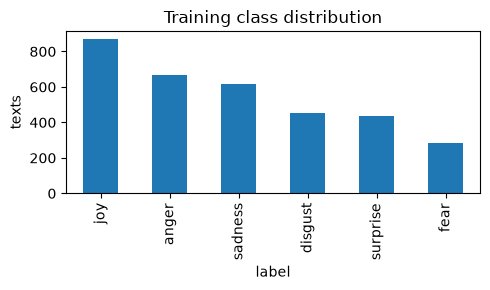

In [12]:
# Class counts after deduplication: share of the training set and size relative to joy
class_counts = train_df["label"].value_counts().reindex(LABELS)
class_table = pd.DataFrame({
    "count": class_counts,
    "% of dataset": (100 * class_counts / class_counts.sum()).round(2),
    "ratio to joy": (class_counts / class_counts["joy"]).round(2),
})
display(class_table)
print("total:", class_counts.sum())

fig, ax = plt.subplots(figsize=(5, 3))
class_counts.plot(kind="bar", ax=ax, color="tab:blue")
ax.set_title("Training class distribution"); ax.set_ylabel("texts")
plt.tight_layout()
save_plot(fig, "1_preprocessing", "class_distribution_train")
plt.show()

          count  mean   std  min   25%   50%   75%    max
label                                                    
anger     667.0  20.3  36.5  2.0   9.0  14.0  22.0  509.0
disgust   451.0  18.7  28.9  1.0   9.0  14.0  22.0  506.0
fear      282.0  17.1  17.5  3.0   9.0  15.0  21.0  242.0
joy       870.0  20.4  36.2  2.0   9.0  14.0  21.0  508.0
sadness   619.0  18.2  20.6  1.0  10.0  15.0  21.0  387.0
surprise  437.0  14.9   8.5  2.0   9.0  14.0  19.0   79.0


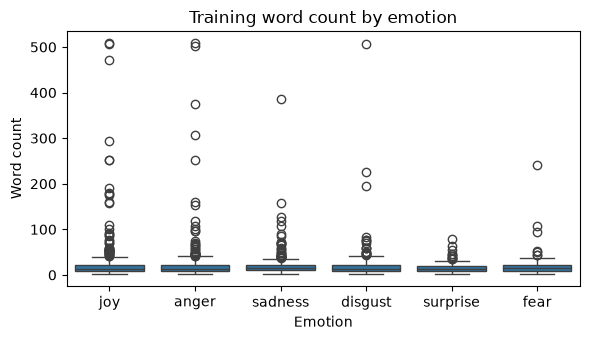

In [13]:
# Text length, counted in tokens, summarized per emotion.
train_df["word_count"] = train_df["tokens"].map(len)
print(train_df.groupby("label")["word_count"].describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))

sns.boxplot(data=train_df, x="label", y="word_count",order=LABELS, ax=ax)
ax.set_title("Training word count by emotion")
ax.set_xlabel("Emotion")
ax.set_ylabel("Word count")

plt.tight_layout()
save_plot(fig, "1_preprocessing", "word_count_by_emotion_boxplot")
plt.show()

### 1.7 Identifying Repetitions

In [14]:
# Unique-token ratio: share of tokens in a post that are distinct (low = repetition loop)
train_df["unique_ratio"] = train_df["tokens"].map(lambda t: len(set(t)) / len(t))
print("loop posts (<30% unique tokens):", (train_df["unique_ratio"] < 0.3).sum())

N_PER_LABEL = 3
PREVIEW_CHARS = 200

# Sort by length, keep the N longest per label, then order by label for display
longest = (train_df.sort_values("word_count", ascending=False)
                   .groupby("label", sort=False)
                   .head(N_PER_LABEL)
                   .sort_values(["label", "word_count"], ascending=[True, False]))

for label, group in longest.groupby("label"):
    print(f"\n=== {label.upper()} ===")
    for _, row in group.iterrows():
        flag = "LOOP" if row.unique_ratio < 0.3 else "    "
        print(f"[{flag}] {row.word_count:4d} tokens | unique {row.unique_ratio:.0%} | "
              f"{row.clean_text[:PREVIEW_CHARS]}...")

loop posts (<30% unique tokens): 27

=== ANGER ===
[LOOP]  509 tokens | unique 4% | I was really shy, in the first place, when I was in charge of the cargo, and I was really in charge of the cargo, and I was in the kitchen, and I was in the kitchen, and I was in the kitchen, and I wa...
[LOOP]  502 tokens | unique 6% | Today 2014 democracy scholars who are waiting for you see you waiting for you Habiba Siraj omn conscience is fighting and we are waiting for the truth in our lives we are afraid of life and we are for...
[LOOP]  375 tokens | unique 5% | The world is a terrible place to live if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it if I can talk about it i...

=== DISGUST ===
[LOOP]  506 tokens | unique 4% | I'm wearing a suit and I'm learning Somali. Oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, oh, 

In [15]:
def collapse_repeats(tokens, max_n=10, max_copies=2):
    """Collapse a phrase of 1..max_n tokens repeated back-to-back into at most max_copies."""
    out = list(tokens)
    for n in range(1, max_n + 1):
        i, res = 0, []
        while i < len(out):
            chunk = out[i:i + n]
            copies = 1
            while len(chunk) == n and out[i + copies * n:i + (copies + 1) * n] == chunk:
                copies += 1
            if copies > 1:
                res.extend(chunk * min(copies, max_copies))
                i += n * copies
            else:
                res.append(out[i])
                i += 1
        out = res
    return out

In [16]:
train_df["tokens"] = train_df["tokens"].map(collapse_repeats)
test_df["tokens"] = test_df["tokens"].map(collapse_repeats)

unique_ratio = lambda toks: len(set(toks)) / len(toks)
print("loop posts (<30% unique tokens):", (train_df["tokens"].map(unique_ratio) < 0.3).sum())
print("longest post (tokens):", train_df["tokens"].map(len).max())

loop posts (<30% unique tokens): 11
longest post (tokens): 153


### 1.8 Final Training & Validation Split

In [17]:
# Unstratified: rows are shuffled and split at random
tr_df, val_df = train_test_split(train_df, test_size=0.2, random_state=SEED)
tr_y = tr_df["label"]
val_y = val_df["label"]

# Stratified: each label keeps the same proportion in both parts
str_tr_df, str_val_df = train_test_split(train_df, test_size=0.2, random_state=SEED,
                                 stratify=train_df["label"])

## 2. Feature Engineering Steps

In [18]:
### Add the code related to the feature engineering steps in cells inside this section
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import os
from sentence_transformers import SentenceTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
import torch
from scipy.special import softmax, expit
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification
from sklearn.pipeline import make_pipeline
import json
from sklearn.model_selection import StratifiedKFold

In [19]:
EMBEDDERS = {
    "minilm": "sentence-transformers/all-MiniLM-L6-v2",
    "mpnet":  "sentence-transformers/all-mpnet-base-v2",
}

EMB_DIR = "data/kaggle/embeddings"
os.makedirs(EMB_DIR, exist_ok=True)

EMOTION_MODELS = {
    "jhartmann": "j-hartmann/emotion-english-distilroberta-base",  # 7 labels, single-label (softmax)
    "samlowe":   "SamLowe/roberta-base-go_emotions",               # 28 labels, multi-label (sigmoid)
}
EMOTION_KIND = {"jhartmann": "single", "samlowe": "multi"}
EMO_DIR = "data/kaggle/emotion_logits"
os.makedirs(EMO_DIR, exist_ok=True)
torch.set_num_threads(6)  # limit CPU threads, leaves room for the kernel

FT_DIR = "data/kaggle/ft"
os.makedirs(FT_DIR, exist_ok=True)
FT_MODELS = {"jhartmann": EMOTION_MODELS["jhartmann"], "samlowe": EMOTION_MODELS["samlowe"]}

In [ ]:
def identity(tokens):
    # Tokens are already lists from preprocessing, so pass them through unchanged
    return tokens

def make_tfidf(**kwargs):
    """TF-IDF over pre-tokenized posts. Uses the tokenizer slot (not analyzer),
    so ngram_range and the other word options still apply."""
    return TfidfVectorizer(tokenizer=identity, preprocessor=identity,
                           lowercase=False, token_pattern=None, **kwargs)

def build_features(train_part, val_part):
    """Fit TF-IDF on the training part only, then transform both parts."""
    vec = make_tfidf()
    X_train = vec.fit_transform(train_part["tokens"])
    X_val = vec.transform(val_part["tokens"])
    return vec, X_train, X_val

def encode_cached(model_name, texts, cache_file):
    """Encode texts with a pretrained sentence embedder, or load a previous run from disk."""
    if os.path.exists(cache_file):
        return np.load(cache_file)
    model = SentenceTransformer(model_name, device="cpu")
    # normalize_embeddings=True gives each vector length 1, the same scale as a TF-IDF row
    emb = model.encode(list(texts), batch_size=32,
                       normalize_embeddings=True, show_progress_bar=True)
    np.save(cache_file, emb)
    return emb

def stack_embeddings(col):
    # A column holding one array per row -> a 2-D matrix (n_posts x dims)
    return np.vstack(col.values)

def make_emb_features(emb_col, emb_weight=1.0, **tfidf_kwargs):
    """TF-IDF (same make_tfidf as the TF-IDF-only model) side by side with one embedding column."""
    return ColumnTransformer(
        [("tfidf", make_tfidf(**tfidf_kwargs), "tokens"),
         ("emb", FunctionTransformer(stack_embeddings), emb_col)],
        transformer_weights={"tfidf": 1.0, "emb": emb_weight})

def make_stack_features(emb_col, emo_cols, **tfidf_kwargs):
    """TF-IDF + one sentence embedding + one block per emotion model's output logits.
    Block weights are set by the grid search (features__transformer_weights)."""
    blocks = [("tfidf", make_tfidf(**tfidf_kwargs), "tokens"),
              ("emb", FunctionTransformer(stack_embeddings), emb_col)]
    for col in emo_cols:
        # Logits are on their own scale (about -5..+5), so standardize each column.
        # Inside the pipeline, the scaler is fitted on each fold's training part only.
        blocks.append((col, make_pipeline(FunctionTransformer(stack_embeddings), StandardScaler()), col))
    return ColumnTransformer(blocks)

def logits_cached(model_name, texts, cache_file, batch_size=32, max_length=256):
    """Raw output logits of a pretrained emotion classifier, one row per text, cached to disk."""
    config = AutoConfig.from_pretrained(model_name)
    labels = [config.id2label[i] for i in range(config.num_labels)]  # column order of the logits
    if os.path.exists(cache_file):
        return np.load(cache_file), labels
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name).eval()
    out = []
    with torch.no_grad():  # inference only, no gradients
        for i in tqdm(range(0, len(texts), batch_size)):
            batch = tok(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt")
            out.append(model(**batch).logits.numpy())
    logits = np.vstack(out)
    np.save(cache_file, logits)
    return logits, labels

def model_text(s):
    return re.sub(r"\s+", " ", html.unescape(s)).strip()

In [21]:
# One feature set per split, each with its own vectorizer
vec_un, X_tr_un, X_val_un = build_features(tr_df, val_df)            # unstratified
vec_st, X_tr_st, X_val_st = build_features(str_tr_df, str_val_df)    # stratified

print("Unstratified:", X_tr_un.shape, X_val_un.shape)   # (2660, 6823) (666, 6823)
print("Stratified:  ", X_tr_st.shape, X_val_st.shape)   # (2660, 6826) (666, 6826)

Unstratified: (2660, 6823) (666, 6823)
Stratified:   (2660, 6826) (666, 6826)


In [22]:
# Embed the collapsed tokens re-joined into text (the same preprocessing TF-IDF sees)
emb_text_train = train_df["tokens"].map(" ".join)
emb_text_test = test_df["tokens"].map(" ".join)

for short, model_name in EMBEDDERS.items():
    train_emb = encode_cached(model_name, emb_text_train, f"{EMB_DIR}/{short}_train.npy")
    test_emb = encode_cached(model_name, emb_text_test, f"{EMB_DIR}/{short}_test.npy")
    train_df[f"emb_{short}"] = list(train_emb)
    test_df[f"emb_{short}"] = list(test_emb)
    print(f"{short}: train {train_emb.shape}, test {test_emb.shape}")

minilm: train (3326, 384), test (1440, 384)
mpnet: train (3326, 768), test (1440, 768)


In [23]:
emo_text_train = train_df["text"].map(model_text).tolist()
emo_text_test = test_df["text"].map(model_text).tolist()

EMO_LABELS = {}
for short, model_name in EMOTION_MODELS.items():
    tr_logits, EMO_LABELS[short] = logits_cached(model_name, emo_text_train, f"{EMO_DIR}/{short}_train.npy")
    te_logits, _ = logits_cached(model_name, emo_text_test, f"{EMO_DIR}/{short}_test.npy")
    train_df[f"emo_{short}"] = list(tr_logits)
    test_df[f"emo_{short}"] = list(te_logits)
    print(short, tr_logits.shape, te_logits.shape, EMO_LABELS[short])

jhartmann (3326, 7) (1440, 7) ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']
samlowe (3326, 28) (1440, 28) ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [24]:
# Fine-tuning settings: changing any of them gives a new cache tag, so the next run retrains
FT_PARAMS = {"epochs": 4, "lr": 2e-5, "batch": 16, "max_len": 128}
FT_TAG = "e{epochs}_lr{lr:g}_b{batch}_len{max_len}".format(**FT_PARAMS)  # e3_lr2e-05_b16_len128
FT_FORCE = False  # True: retrain even if files with this tag exist

# Fold ids computed here (pinned sklearn), so the GPU script needs no sklearn
ft_folds = np.zeros(len(train_df), dtype=int)
ft_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, va) in enumerate(ft_skf.split(train_df, train_df["label"])):
    ft_folds[va] = k

# Same raw text the frozen emotion models saw
with open(f"{FT_DIR}/inputs.json", "w") as f:
    json.dump({"labels": LABELS, "seed": SEED, "params": FT_PARAMS, "tag": FT_TAG,
               "train_text": emo_text_train, "test_text": emo_text_test,
               "train_label": train_df["label"].tolist(), "fold": ft_folds.tolist()}, f)

In [25]:
%%writefile finetune_oof.py
"""Out-of-fold fine-tuning of a pretrained emotion classifier on the competition's 6 labels.
Run with the separate GPU environment. Reads and writes only data/kaggle/ft/."""
import sys, json, time
import numpy as np, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

short, model_name = sys.argv[1], sys.argv[2]
FT_DIR = "data/kaggle/ft"
cfg = json.load(open(f"{FT_DIR}/inputs.json"))
LABELS, SEED = cfg["labels"], cfg["seed"]
train_text, test_text = cfg["train_text"], cfg["test_text"]
y = np.array([LABELS.index(l) for l in cfg["train_label"]])
fold = np.array(cfg["fold"])
P, TAG = cfg["params"], cfg["tag"]
EPOCHS, LR, BATCH, MAX_LEN = P["epochs"], P["lr"], P["batch"], P["max_len"]
print(f"{short}: settings {P}", flush=True)
device = "cuda"
tok = AutoTokenizer.from_pretrained(model_name)

def batches(texts, labels=None, shuffle=False, seed=0):
    """Tokenized mini-batches on the GPU; shuffled with a fixed seed when training."""
    idx = np.arange(len(texts))
    if shuffle:
        np.random.default_rng(seed).shuffle(idx)
    for i in range(0, len(idx), BATCH):
        b = idx[i:i + BATCH]
        enc = tok([texts[j] for j in b], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt")
        if labels is not None:
            enc["labels"] = torch.tensor(labels[b])
        yield enc.to(device)

@torch.no_grad()
def predict(model, texts):
    model.eval()
    out = []
    for enc in batches(texts):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out.append(model(**enc).logits.float().cpu().numpy())
    return np.vstack(out)

def macro_f1(y_true, y_pred, n=len(LABELS)):
    """Mean of per-class F1 (numpy only, no sklearn in this environment)."""
    f1s = []
    for c in range(n):
        tp = np.sum((y_pred == c) & (y_true == c))
        prec = tp / max(np.sum(y_pred == c), 1)
        rec = tp / max(np.sum(y_true == c), 1)
        f1s.append(0 if tp == 0 else 2 * prec * rec / (prec + rec))
    return float(np.mean(f1s))

oof = np.zeros((len(train_text), len(LABELS)), dtype=np.float32)
test_sum = np.zeros((len(test_text), len(LABELS)), dtype=np.float32)
n_folds = len(set(fold))
for k in range(n_folds):
    t0 = time.time()
    torch.manual_seed(SEED + k)
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    # New 6-class head on the pretrained body. problem_type overrides SamLowe's
    # multi-label setting, so the loss is softmax cross-entropy for one label per post.
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)},
        problem_type="single_label_classification", ignore_mismatched_sizes=True).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * int(np.ceil(len(tr) / BATCH))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    tr_text = [train_text[i] for i in tr]
    for epoch in range(EPOCHS):
        model.train()
        total, n_batches = 0.0, 0
        for enc in batches(tr_text, y[tr], shuffle=True, seed=SEED * 100 + k * 10 + epoch):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = model(**enc).loss
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            total += loss.item()
            n_batches += 1
        print(f"{short} fold {k} epoch {epoch}: mean train loss {total / n_batches:.3f}, train loss {total:.1f}", flush=True)
        ep_pred = predict(model, [train_text[i] for i in va]).argmax(1)
        print(f"{short} fold {k} epoch {epoch}: OOF macro F1 {macro_f1(y[va], ep_pred):.3f}", flush=True)
        model.train()  # predict() switched to eval mode
    oof[va] = predict(model, [train_text[i] for i in va])   # only this fold: unseen by this model
    va_pred = oof[va].argmax(1)
    print(f"{short} fold {k}: OOF accuracy {(va_pred == y[va]).mean():.3f}, "
          f"macro F1 {macro_f1(y[va], va_pred):.3f}, {time.time() - t0:.0f}s, "
          f"peak GPU {torch.cuda.max_memory_allocated() / 2**30:.1f} GB", flush=True)
    test_sum += predict(model, test_text)
    del model, opt
    torch.cuda.empty_cache()

np.save(f"{FT_DIR}/{short}_{TAG}_oof_train.npy", oof)
np.save(f"{FT_DIR}/{short}_{TAG}_test.npy", test_sum / n_folds)
print(f"{short}: OOF macro F1 over all folds {macro_f1(y, oof.argmax(1)):.3f}")
print("saved", short)

Overwriting finetune_oof.py


In [26]:
GPU_PY = os.path.expanduser("~/.venvs/dm2026-gpu/bin/python")
for short, model_name in FT_MODELS.items():
    cached = os.path.exists(f"{FT_DIR}/{short}_{FT_TAG}_oof_train.npy")
    if FT_FORCE or not cached:
        !{GPU_PY} finetune_oof.py {short} {model_name}
    else:
        print(f"{short}: cached for {FT_TAG}, skipping")

jhartmann: cached for e4_lr2e-05_b16_len128, skipping
samlowe: cached for e4_lr2e-05_b16_len128, skipping


In [27]:
# Fine-tuned logits: out-of-fold for train, 5-fold average for test. Columns are in LABELS order.
for short in FT_MODELS:
    train_df[f"emo_ft_{short}"] = list(np.load(f"{FT_DIR}/{short}_{FT_TAG}_oof_train.npy"))
    test_df[f"emo_ft_{short}"] = list(np.load(f"{FT_DIR}/{short}_{FT_TAG}_test.npy"))
    print(short, FT_TAG, np.vstack(train_df[f"emo_ft_{short}"]).shape,
          np.vstack(test_df[f"emo_ft_{short}"]).shape)

jhartmann e4_lr2e-05_b16_len128 (3326, 6) (1440, 6)
samlowe e4_lr2e-05_b16_len128 (3326, 6) (1440, 6)


In [28]:
feat_tr_df = train_df.loc[str_tr_df.index]
feat_val_df = train_df.loc[str_val_df.index]

## 3. Model Implementation Steps

In [29]:
### Add the code related to the model implementation steps in cells inside this section
import itertools
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

In [30]:
EKMAN_GROUPS = {
    "anger":    ["anger", "annoyance", "disapproval"],
    "disgust":  ["disgust"],
    "fear":     ["fear", "nervousness"],
    "joy":      ["joy", "admiration", "amusement", "approval", "caring", "desire", "excitement",
                 "gratitude", "love", "optimism", "pride", "relief"],
    "sadness":  ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
}

In [31]:
def plot_confusion_matrix(cm, classes, title="Confusion matrix", filename=None):
    '''Modified from scikit-learn's confusion-matrix example.
    With a filename, the plot is also saved to plots/3_model_implementation/.'''
    # One square per (true label, predicted label) pair, shaded by its count:
    # the more tweets in a square, the darker it is.
    fig, ax = plt.subplots(figsize=(8, 5))
    im = ax.imshow(cm, interpolation="nearest", cmap=sns.cubehelix_palette(as_cmap=True))
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]),
           xticklabels=classes, yticklabels=classes, title=title,
           xlabel="Predicted label", ylabel="True label")
    # Print the count inside each square, switching to white text on the dark ones.
    thresh = cm.max() / 2.0
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        ax.text(j, i, format(cm[i, j], "d"), horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    if filename:
        save_plot(fig, "3_model_implementation", filename)
    plt.show()

def train_and_evaluate(X_train, y_train, X_val, y_val, title, filename=None):
    """Train a default LinearSVC on given features and report validation results."""
    clf = LinearSVC()
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)

    print(f"=== {title} ===")
    print(classification_report(y_val, pred))
    plot_confusion_matrix(confusion_matrix(y_val, pred, labels=LABELS), LABELS, title=title, filename=filename)
    return clf, pred

def to_six(logits, labels, kind):
    """Raw model outputs -> probabilities over our 6 LABELS (columns in LABELS order)."""
    idx = {l: i for i, l in enumerate(labels)}
    if kind == "single":   # one softmax over all labels; keep our 6 and drop neutral
        assert set(LABELS) <= set(labels)
        six = softmax(logits, axis=1)[:, [idx[l] for l in LABELS]]
    else:                  # independent sigmoids; the strongest member of each group
        p = expit(logits)
        six = np.column_stack([p[:, [idx[m] for m in EKMAN_GROUPS[l]]].max(axis=1) for l in LABELS])
    return six / six.sum(axis=1, keepdims=True)  # renormalize over the 6 emotions

=== Unstratified ===
              precision    recall  f1-score   support

       anger       0.49      0.46      0.47       131
     disgust       0.40      0.30      0.34        90
        fear       0.51      0.52      0.52        44
         joy       0.58      0.69      0.63       175
     sadness       0.53      0.55      0.54       123
    surprise       0.55      0.51      0.53       103

    accuracy                           0.53       666
   macro avg       0.51      0.51      0.51       666
weighted avg       0.52      0.53      0.52       666



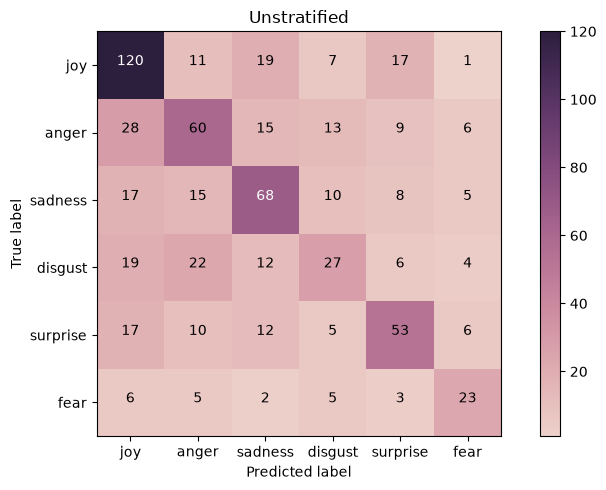

In [32]:
clf_un, pred_un = train_and_evaluate(X_tr_un, tr_df["label"],
                                     X_val_un, val_df["label"], "Unstratified",
                                     filename="cm_tfidf_svm_default_unstratified")

=== Stratified ===
              precision    recall  f1-score   support

       anger       0.41      0.43      0.42       134
     disgust       0.38      0.28      0.32        90
        fear       0.50      0.30      0.38        56
         joy       0.55      0.71      0.62       174
     sadness       0.48      0.47      0.48       124
    surprise       0.49      0.44      0.47        88

    accuracy                           0.48       666
   macro avg       0.47      0.44      0.45       666
weighted avg       0.47      0.48      0.47       666



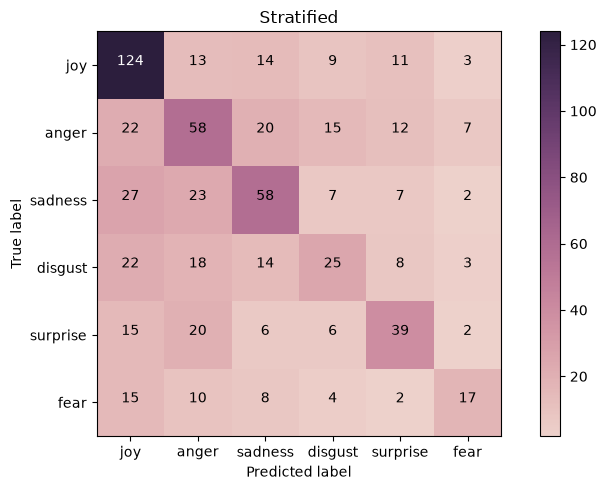

In [33]:
clf_st, pred_st = train_and_evaluate(X_tr_st, str_tr_df["label"],
                                     X_val_st, str_val_df["label"], "Stratified",
                                     filename="cm_tfidf_svm_default_stratified")

In [34]:
# Grid search over params
pipe = Pipeline([
    ("tfidf", make_tfidf()),
    ("svm", LinearSVC()),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__min_df": [1, 2, 3, 4],
    "tfidf__sublinear_tf": [False, True],
    "svm__C": [0.001, 0.05, 0.1, 0.3, 0.5, 1.0, 2, 3],
    "svm__class_weight": [None, "balanced"],
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipe, param_grid, cv=skf, scoring="f1_macro",
                      n_jobs=6, return_train_score=True)
search.fit(str_tr_df["tokens"], str_tr_df["label"]) # tune on the training split only

results = pd.DataFrame(search.cv_results_)
cols = ["params", "mean_test_score", "std_test_score", "mean_train_score"]
display(results.sort_values("rank_test_score")[cols].head(10))

,params,mean_test_score,std_test_score,mean_train_score
169,"{'svm__C': 0.3, 'svm__class_weight': 'balanced...",0.488084,0.012906,0.968897
168,"{'svm__C': 0.3, 'svm__class_weight': 'balanced...",0.484893,0.011711,0.965279
216,"{'svm__C': 0.5, 'svm__class_weight': 'balanced...",0.483438,0.011774,0.981859
217,"{'svm__C': 0.5, 'svm__class_weight': 'balanced...",0.482380,0.015433,0.983953
193,"{'svm__C': 0.5, 'svm__class_weight': None, 'tf...",0.479576,0.015573,0.982117
151,"{'svm__C': 0.3, 'svm__class_weight': None, 'tf...",0.478381,0.013960,0.901188
175,"{'svm__C': 0.3, 'svm__class_weight': 'balanced...",0.477605,0.009283,0.915344
145,"{'svm__C': 0.3, 'svm__class_weight': None, 'tf...",0.476535,0.011792,0.964163
199,"{'svm__C': 0.5, 'svm__class_weight': None, 'tf...",0.476521,0.013027,0.937100
192,"{'svm__C': 0.5, 'svm__class_weight': None, 'tf...",0.476312,0.012514,0.980450


best params: {'svm__C': 0.3, 'svm__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': True}
CV macro F1: 0.488
              precision    recall  f1-score   support

       anger       0.44      0.47      0.46       134
     disgust       0.36      0.31      0.34        90
        fear       0.46      0.38      0.41        56
         joy       0.59      0.68      0.63       174
     sadness       0.53      0.51      0.52       124
    surprise       0.51      0.48      0.49        88

    accuracy                           0.50       666
   macro avg       0.48      0.47      0.48       666
weighted avg       0.50      0.50      0.50       666



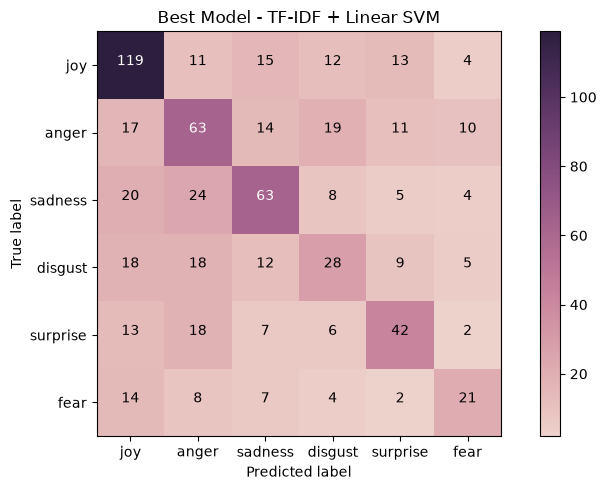

In [35]:
# Final check on the held-out split, which the grid search never saw
val_pred = search.predict(str_val_df["tokens"])
print("best params:", search.best_params_)
print(f"CV macro F1: {search.best_score_:.3f}")
print(classification_report(str_val_df["label"], val_pred))
plot_confusion_matrix(confusion_matrix(str_val_df["label"], val_pred, labels=LABELS), LABELS, title="Best Model - TF-IDF + Linear SVM",
                      filename="cm_tfidf_svm_best_grid")

In [36]:
final_model = clone(search.best_estimator_)
final_model.fit(train_df["tokens"], train_df["label"])
test_pred = final_model.predict(test_df["tokens"])

sample = pd.read_csv(f"{DATA_DIR}/sampleSubmission.csv")
submission = pd.DataFrame({"id": test_df["post_id"], "label": test_pred})
assert len(submission) == len(sample) and set(submission.id) == set(sample.post_id)
submission.to_csv("submission_tfidf_svm.csv", index=False)
print(submission["label"].value_counts(normalize=True).round(3))

label
joy         0.267
anger       0.215
sadness     0.173
surprise    0.139
disgust     0.128
fear        0.078
Name: proportion, dtype: float64


In [37]:
emb_weights = [{"tfidf": 1, "emb": w} for w in [0.1, 0.5, 1, 2]]
emb_param_grid = [
    {   # Linear SVM
        "features__transformer_weights": emb_weights,
        "clf": [LinearSVC(class_weight="balanced")],
        "clf__C": [0.01, 0.03, 0.05, 0.1, 0.3, 1.0, 1.5, 2.0, 3.0],
    },
    {   # Logistic regression
        "features__transformer_weights": emb_weights,
        "clf": [LogisticRegression(class_weight="balanced", max_iter=3000)],
        "clf__C": [0.01, 0.03, 0.05, 0.1, 0.3, 1.0, 1.5, 2.0, 3.0],
    },
]

# Reference row: the TF-IDF-only search from earlier
comparison = [{"model": "TF-IDF only", "cv_macro_f1": search.best_score_,
               "holdout_macro_f1": f1_score(str_val_df["label"], search.predict(str_val_df["tokens"]), average="macro")}]

emb_searches = {}
for short in EMBEDDERS:
    emb_cols = ["tokens", f"emb_{short}"]
    emb_pipe = Pipeline([
        ("features", make_emb_features(f"emb_{short}", sublinear_tf=True)),
        ("clf", LinearSVC(class_weight="balanced")),
    ])
    emb_search = GridSearchCV(emb_pipe, emb_param_grid, cv=skf, # same folds as TF-IDF only
                              scoring="f1_macro", n_jobs=6)
    emb_search.fit(feat_tr_df[emb_cols], feat_tr_df["label"])
    emb_searches[short] = emb_search

    r = pd.DataFrame(emb_search.cv_results_)
    r["clf_name"] = r["param_clf"].map(lambda m: type(m).__name__)
    best_per_clf = r.loc[r.groupby("clf_name")["mean_test_score"].idxmax(),
                         ["clf_name", "param_clf__C", "mean_test_score", "std_test_score"]]
    print(short); display(best_per_clf.round(3))

    holdout_pred = emb_search.predict(feat_val_df[emb_cols])
    best_clf = emb_search.best_estimator_.named_steps["clf"]
    comparison.append({"model": f"TF-IDF + {short}", "cv_macro_f1": emb_search.best_score_,
                       "holdout_macro_f1": f1_score(feat_val_df["label"], holdout_pred, average="macro"),
                       "clf": type(best_clf).__name__, "emb_weight": emb_search.best_params_["features__transformer_weights"]["emb"],
                       "best_params": emb_search.best_params_})

minilm


,clf_name,param_clf__C,mean_test_score,std_test_score
14,LinearSVC,0.1,0.538,0.019
58,LogisticRegression,1.0,0.531,0.017


mpnet


,clf_name,param_clf__C,mean_test_score,std_test_score
10,LinearSVC,0.05,0.544,0.012
61,LogisticRegression,1.50,0.542,0.015


,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}"
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}"


              precision    recall  f1-score   support

       anger       0.51      0.61      0.55       134
     disgust       0.44      0.31      0.37        90
        fear       0.49      0.57      0.53        56
         joy       0.66      0.78      0.71       174
     sadness       0.55      0.43      0.48       124
    surprise       0.50      0.41      0.45        88

    accuracy                           0.55       666
   macro avg       0.52      0.52      0.52       666
weighted avg       0.54      0.55      0.54       666



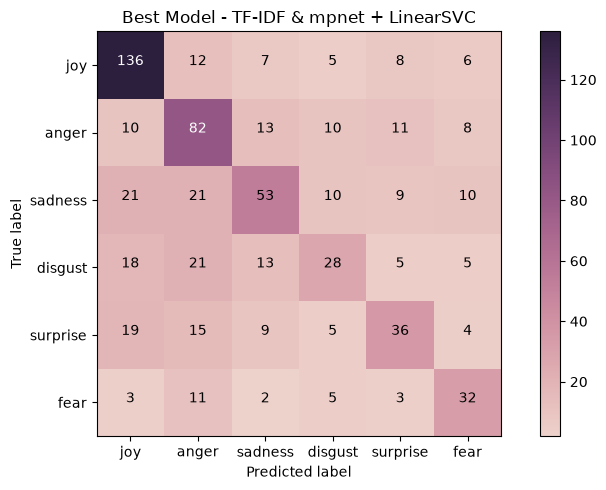

In [38]:
best_short = max(emb_searches, key=lambda short: emb_searches[short].best_score_)
best_cols = ["tokens", f"emb_{best_short}"]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))
emb_val_pred = emb_searches[best_short].predict(feat_val_df[best_cols])

print(classification_report(feat_val_df["label"], emb_val_pred))
best_clf_name = type(emb_searches[best_short].best_estimator_.named_steps["clf"]).__name__
plot_confusion_matrix(confusion_matrix(feat_val_df["label"], emb_val_pred, labels=LABELS),
                      LABELS, title=f"Best Model - TF-IDF & {best_short} + {best_clf_name}",
                      filename=f"cm_tfidf_{best_short}_{best_clf_name}")

In [39]:
print("CV macro F1 per embedder:",
      {short: round(s.best_score_, 3) for short, s in emb_searches.items()})
print("selected:", best_short, "with", emb_searches[best_short].best_params_)

emb_final_model = clone(emb_searches[best_short].best_estimator_)
emb_final_model.fit(train_df[best_cols], train_df["label"]) # all training data
emb_test_pred = emb_final_model.predict(test_df[best_cols])

emb_submission = pd.DataFrame({"id": test_df["post_id"], "label": emb_test_pred})
assert len(emb_submission) == 1440 and set(emb_submission["label"]) <= set(LABELS)
assert len(emb_submission) == len(sample) and set(emb_submission.id) == set(sample.post_id)
emb_submission.to_csv(f"submission_tfidf_{best_short}_{best_clf_name}.csv", index=False)
print(emb_submission["label"].value_counts(normalize=True).round(3))

CV macro F1 per embedder: {'minilm': np.float64(0.538), 'mpnet': np.float64(0.544)}
selected: mpnet with {'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}
label
joy         0.277
anger       0.214
sadness     0.174
surprise    0.129
disgust     0.117
fear        0.089
Name: proportion, dtype: float64


,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params,train_macro_f1
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN
3,jhartmann zero-shot,NaN,0.551,NaN,NaN,NaN,0.569
4,samlowe zero-shot,NaN,0.511,NaN,NaN,NaN,0.564


=== Best zero-shot: jhartmann (holdout) ===
              precision    recall  f1-score   support

       anger       0.53      0.47      0.50       134
     disgust       0.37      0.57      0.45        90
        fear       0.53      0.54      0.53        56
         joy       0.86      0.70      0.77       174
     sadness       0.61      0.44      0.51       124
    surprise       0.47      0.65      0.55        88

    accuracy                           0.57       666
   macro avg       0.56      0.56      0.55       666
weighted avg       0.60      0.57      0.57       666



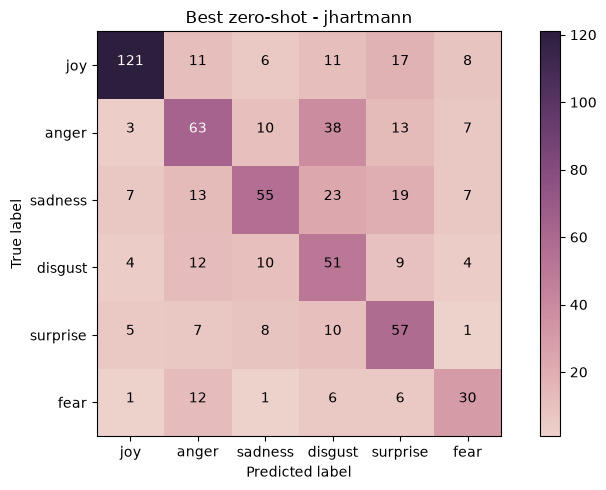

In [40]:
comparison = [row for row in comparison if "zero-shot" not in row["model"]]  # no duplicate rows on re-run

pt_results = {}
for short in EMOTION_MODELS:
    probs = {name: to_six(np.vstack(df[f"emo_{short}"]), EMO_LABELS[short], EMOTION_KIND[short])
             for name, df in [("holdout", feat_val_df), ("train", train_df)]}
    pt_val_pred = np.array(LABELS)[probs["holdout"].argmax(axis=1)]
    pt_train_pred = np.array(LABELS)[probs["train"].argmax(axis=1)]

    pt_results[short] = {"val_pred": pt_val_pred,
                         "train_f1": f1_score(train_df["label"], pt_train_pred, average="macro")}
    comparison.append({"model": f"{short} zero-shot",
                       "holdout_macro_f1": f1_score(feat_val_df["label"], pt_val_pred, average="macro"),
                       "train_macro_f1": pt_results[short]["train_f1"]})

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))

# Select on all of train (nothing was fitted, so no leakage), then report on the holdout
best_pt = max(pt_results, key=lambda short: pt_results[short]["train_f1"])
print(f"=== Best zero-shot: {best_pt} (holdout) ===")
print(classification_report(feat_val_df["label"], pt_results[best_pt]["val_pred"]))
plot_confusion_matrix(confusion_matrix(feat_val_df["label"], pt_results[best_pt]["val_pred"], labels=LABELS),
                      LABELS, title=f"Best zero-shot - {best_pt}",
                      filename=f"cm_zero_shot_{best_pt}")

,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params,train_macro_f1
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN
3,jhartmann zero-shot,NaN,0.551,NaN,NaN,NaN,0.569
4,samlowe zero-shot,NaN,0.511,NaN,NaN,NaN,0.564
5,jhartmann fine-tuned (OOF),0.615,0.600,NaN,NaN,NaN,NaN
6,samlowe fine-tuned (OOF),0.616,0.591,NaN,NaN,NaN,NaN


,jhartmann zero-shot,samlowe zero-shot,jhartmann fine-tuned,samlowe fine-tuned
joy,0.77,0.67,0.77,0.75
anger,0.50,0.52,0.55,0.62
sadness,0.51,0.54,0.60,0.61
disgust,0.45,0.32,0.49,0.43
surprise,0.55,0.45,0.61,0.58
fear,0.53,0.57,0.58,0.56


=== jhartmann fine-tuned (holdout) ===
              precision    recall  f1-score   support

       anger       0.53      0.57      0.55       134
     disgust       0.49      0.49      0.49        90
        fear       0.62      0.55      0.58        56
         joy       0.72      0.82      0.77       174
     sadness       0.65      0.56      0.60       124
    surprise       0.65      0.57      0.61        88

    accuracy                           0.62       666
   macro avg       0.61      0.59      0.60       666
weighted avg       0.62      0.62      0.62       666



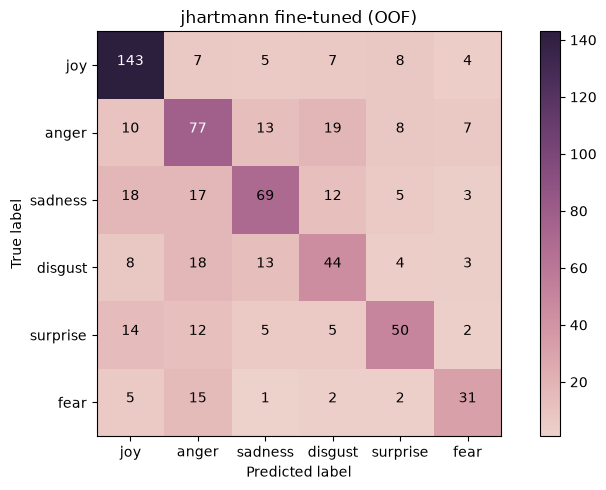

=== samlowe fine-tuned (holdout) ===
              precision    recall  f1-score   support

       anger       0.63      0.61      0.62       134
     disgust       0.42      0.43      0.43        90
        fear       0.60      0.52      0.56        56
         joy       0.70      0.80      0.75       174
     sadness       0.62      0.60      0.61       124
    surprise       0.64      0.53      0.58        88

    accuracy                           0.62       666
   macro avg       0.60      0.58      0.59       666
weighted avg       0.62      0.62      0.62       666



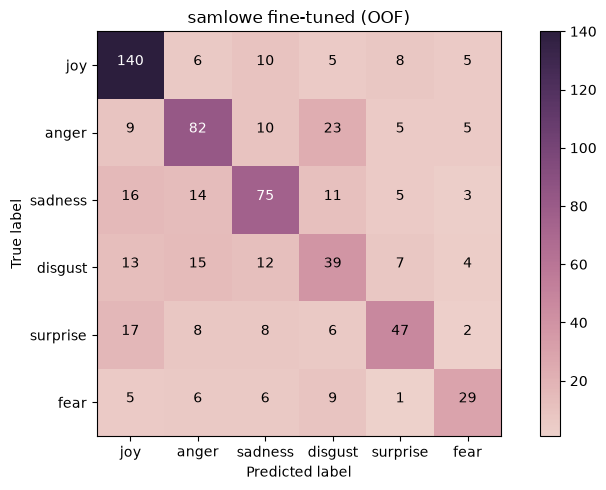

In [41]:
comparison = [row for row in comparison if "fine-tuned" not in row["model"]]
ft_preds = {}
for short in FT_MODELS:
    oof_pred = np.array(LABELS)[np.vstack(train_df[f"emo_ft_{short}"]).argmax(axis=1)]
    val_pred = np.array(LABELS)[np.vstack(feat_val_df[f"emo_ft_{short}"]).argmax(axis=1)]
    ft_preds[short] = val_pred
    comparison.append({"model": f"{short} fine-tuned (OOF)",
                       "cv_macro_f1": f1_score(train_df["label"], oof_pred, average="macro"),  # 5-fold CV over all train
                       "holdout_macro_f1": f1_score(feat_val_df["label"], val_pred, average="macro")})

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))

# Per class: frozen zero-shot vs fine-tuned, same holdout posts
per_class = pd.DataFrame({
    **{f"{s} zero-shot": f1_score(feat_val_df["label"], pt_results[s]["val_pred"], labels=LABELS, average=None)
       for s in pt_results},
    **{f"{s} fine-tuned": f1_score(feat_val_df["label"], p, labels=LABELS, average=None)
       for s, p in ft_preds.items()},
}, index=LABELS)
display(per_class.round(2))

for short, p in ft_preds.items():
    print(f"=== {short} fine-tuned (holdout) ===")
    print(classification_report(feat_val_df["label"], p))
    plot_confusion_matrix(confusion_matrix(feat_val_df["label"], p, labels=LABELS),
                          LABELS, title=f"{short} fine-tuned (OOF)",
                          filename=f"cm_finetuned_{short}")

In [42]:
EMO_SETS = {
    "jh+sl":             ["emo_jhartmann", "emo_samlowe"], # current best (reference)
    "ft_jh+ft_sl":       ["emo_ft_jhartmann", "emo_ft_samlowe"],
    "ft_sl+jh+sl":       ["emo_ft_samlowe", "emo_jhartmann", "emo_samlowe"],
    "ft_jh+jh+sl":       ["emo_ft_jhartmann", "emo_jhartmann", "emo_samlowe"],
    "ft_jh+ft_sl+jh+sl": ["emo_ft_jhartmann", "emo_ft_samlowe", "emo_jhartmann", "emo_samlowe"],
}
stack_emb_col = f"emb_{best_short}"  # best embedder from the previous search (mpnet)
emb_ws, frozen_ws, ft_ws = [0.5, 1, 1.5], [0.2, 0.4, 0.6], [0.2, 0.4, 0.7, 1.0]

def weight_grid(emo_cols):
    """One weight for the frozen emotion blocks and one for the fine-tuned ones."""
    has_ft = any(c.startswith("emo_ft_") for c in emo_cols)
    has_frozen = any(not c.startswith("emo_ft_") for c in emo_cols)
    grid = []
    for e in emb_ws:
        for wf in (frozen_ws if has_frozen else [None]):
            for wt in (ft_ws if has_ft else [None]):
                grid.append({"tfidf": 1, "emb": e,
                             **{c: (wt if c.startswith("emo_ft_") else wf) for c in emo_cols}})
    return grid

comparison = [row for row in comparison if not row["model"].startswith("stack")]  # no duplicates on re-run
stack_searches = {}
for name, emo_cols in EMO_SETS.items():
    stack_cols = ["tokens", stack_emb_col] + emo_cols
    weights = weight_grid(emo_cols)
    stack_param_grid = [
        {"features__transformer_weights": weights,
         "clf": [LinearSVC(class_weight="balanced", max_iter=3000)], "clf__C": [0.005, 0.01, 0.02, 0.03, 0.05, 0.1]},
        {"features__transformer_weights": weights,
         "clf": [LogisticRegression(class_weight="balanced", max_iter=3000)], "clf__C": [0.3, 0.5, 1, 1.5, 2, 3]},
    ]
    stack_pipe = Pipeline([
        ("features", make_stack_features(stack_emb_col, emo_cols, sublinear_tf=True)),
        ("clf", LinearSVC(class_weight="balanced")),
    ])
    stack_search = GridSearchCV(stack_pipe, stack_param_grid, cv=skf,  # same folds as before
                                scoring="f1_macro", n_jobs=8)
    stack_search.fit(feat_tr_df[stack_cols], feat_tr_df["label"])
    stack_searches[name] = stack_search

    stack_holdout_pred = stack_search.predict(feat_val_df[stack_cols])
    bp = stack_search.best_params_
    comparison.append({"model": f"stack: TF-IDF + {best_short} + {name}",
                       "cv_macro_f1": stack_search.best_score_,
                       "holdout_macro_f1": f1_score(feat_val_df["label"], stack_holdout_pred, average="macro"),
                       "cv_std": stack_search.cv_results_["std_test_score"][stack_search.best_index_],
                       "weights": bp["features__transformer_weights"],
                       "clf": type(bp["clf"]).__name__,
                       "best_params": bp})

,model,cv_macro_f1,holdout_macro_f1,clf,emb_weight,best_params,train_macro_f1,cv_std,weights
0,TF-IDF only,0.488,0.476,NaN,NaN,NaN,NaN,NaN,NaN
1,TF-IDF + minilm,0.538,0.507,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.1, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN,NaN,NaN
2,TF-IDF + mpnet,0.544,0.515,LinearSVC,1.0,"{'clf': LinearSVC(class_weight='balanced'), 'clf__C': 0.05, 'features__transformer_weights': {'tfidf': 1, 'emb': 1}}",NaN,NaN,NaN
3,jhartmann zero-shot,NaN,0.551,NaN,NaN,NaN,0.569,NaN,NaN
4,samlowe zero-shot,NaN,0.511,NaN,NaN,NaN,0.564,NaN,NaN
5,jhartmann fine-tuned (OOF),0.615,0.600,NaN,NaN,NaN,NaN,NaN,NaN
6,samlowe fine-tuned (OOF),0.616,0.591,NaN,NaN,NaN,NaN,NaN,NaN
7,stack: TF-IDF + mpnet + jh+sl,0.639,0.633,LinearSVC,NaN,"{'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.03, 'features__transformer_weights': {'tfidf': 1, 'emb': 1, 'emo_jhartmann': 0.4, 'emo_samlowe': 0.4}}",NaN,0.023,"{'tfidf': 1, 'emb': 1, 'emo_jhartmann': 0.4, 'emo_samlowe': 0.4}"
8,stack: TF-IDF + mpnet + ft_jh+ft_sl,0.640,0.623,LinearSVC,NaN,"{'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.01, 'features__transformer_weights': {'tfidf': 1, 'emb': 1.5, 'emo_ft_jhartmann': 0.2, 'emo_ft_samlowe': 0.2}}",NaN,0.010,"{'tfidf': 1, 'emb': 1.5, 'emo_ft_jhartmann': 0.2, 'emo_ft_samlowe': 0.2}"
9,stack: TF-IDF + mpnet + ft_sl+jh+sl,0.643,0.622,LinearSVC,NaN,"{'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.01, 'features__transformer_weights': {'tfidf': 1, 'emb': 1.5, 'emo_ft_samlowe': 0.2, 'emo_jhartmann': 0.2, 'emo_samlowe': 0.2}}",NaN,0.017,"{'tfidf': 1, 'emb': 1.5, 'emo_ft_samlowe': 0.2, 'emo_jhartmann': 0.2, 'emo_samlowe': 0.2}"


=== Best stack: ft_sl+jh+sl + LinearSVC (holdout) ===
              precision    recall  f1-score   support

       anger       0.59      0.63      0.61       134
     disgust       0.54      0.43      0.48        90
        fear       0.59      0.62      0.61        56
         joy       0.74      0.83      0.78       174
     sadness       0.66      0.60      0.63       124
    surprise       0.64      0.60      0.62        88

    accuracy                           0.65       666
   macro avg       0.63      0.62      0.62       666
weighted avg       0.64      0.65      0.64       666



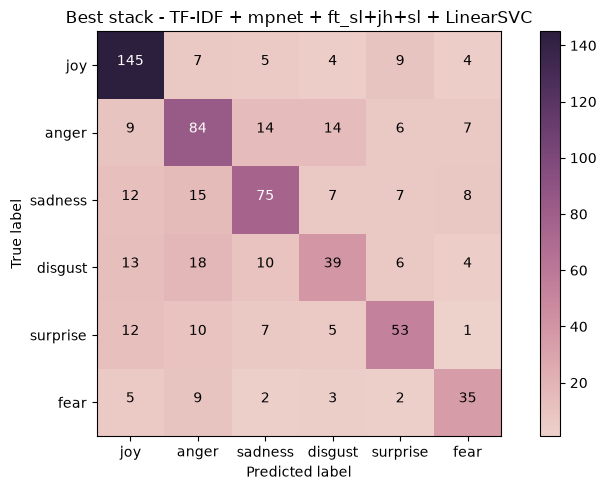

In [43]:
best_stack = max(stack_searches, key=lambda name: stack_searches[name].best_score_)
best_stack_cols = ["tokens", stack_emb_col] + EMO_SETS[best_stack]
best_stack_clf = type(stack_searches[best_stack].best_params_["clf"]).__name__

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(comparison).round(3))

stack_val_pred = stack_searches[best_stack].predict(feat_val_df[best_stack_cols])
print(f"=== Best stack: {best_stack} + {best_stack_clf} (holdout) ===")
print(classification_report(feat_val_df["label"], stack_val_pred))
plot_confusion_matrix(confusion_matrix(feat_val_df["label"], stack_val_pred, labels=LABELS),
                      LABELS, title=f"Best stack - TF-IDF + {best_short} + {best_stack} + {best_stack_clf}",
                      filename=f"cm_stack_{best_short}_{best_stack}_{best_stack_clf}")

In [44]:
print("CV macro F1 per set:", {n: round(s.best_score_, 3) for n, s in stack_searches.items()})
print("selected:", best_stack, "with", stack_searches[best_stack].best_params_)

stack_final_model = clone(stack_searches[best_stack].best_estimator_)
stack_final_model.fit(train_df[best_stack_cols], train_df["label"])  # all training data
stack_test_pred = stack_final_model.predict(test_df[best_stack_cols])

stack_submission = pd.DataFrame({"id": test_df["post_id"], "label": stack_test_pred})
assert len(stack_submission) == len(sample) and set(stack_submission.id) == set(sample.post_id)
assert set(stack_submission["label"]) <= set(LABELS)
stack_submission.to_csv(f"submission_stack_{best_short}_{best_stack}_{best_stack_clf}.csv", index=False)
print(stack_submission["label"].value_counts(normalize=True).round(3))

CV macro F1 per set: {'jh+sl': np.float64(0.639), 'ft_jh+ft_sl': np.float64(0.64), 'ft_sl+jh+sl': np.float64(0.643), 'ft_jh+jh+sl': np.float64(0.641), 'ft_jh+ft_sl+jh+sl': np.float64(0.641)}
selected: ft_sl+jh+sl with {'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.01, 'features__transformer_weights': {'tfidf': 1, 'emb': 1.5, 'emo_ft_samlowe': 0.2, 'emo_jhartmann': 0.2, 'emo_samlowe': 0.2}}
label
joy         0.269
anger       0.214
sadness     0.184
surprise    0.153
disgust     0.096
fear        0.084
Name: proportion, dtype: float64


In [46]:
# Second final submission: the full stack with both fine-tuned and both frozen
# emotion blocks. Tied with the primary in CV, with different errors, so it is a hedge.
full_set = "ft_jh+ft_sl+jh+sl"
full_cols = ["tokens", stack_emb_col] + EMO_SETS[full_set]
full_search = stack_searches[full_set]
full_clf = type(full_search.best_params_["clf"]).__name__
full_holdout = f1_score(feat_val_df["label"], full_search.predict(feat_val_df[full_cols]), average="macro")
print(f"{full_set}: CV {full_search.best_score_:.3f}, holdout {full_holdout:.3f}")
print("params:", full_search.best_params_)

full_final_model = clone(full_search.best_estimator_)
full_final_model.fit(train_df[full_cols], train_df["label"])  # all training data
full_test_pred = full_final_model.predict(test_df[full_cols])

full_submission = pd.DataFrame({"id": test_df["post_id"], "label": full_test_pred})
assert len(full_submission) == len(sample) and set(full_submission.id) == set(sample.post_id)
assert set(full_submission["label"]) <= set(LABELS)
full_file = f"submission_stack_{best_short}_{full_set}_{full_clf}.csv"
full_submission.to_csv(full_file, index=False)
print("written:", full_file)
print(full_submission["label"].value_counts(normalize=True).round(3))

# How different is it from the primary (frozen jh+sl stack, public 0.646)?
primary = pd.read_csv("submission_stack_mpnet_jhartmann+samlowe_LinearSVC.csv")
print("agreement with primary:", (full_submission["label"].values == primary["label"].values).mean().round(3))

ft_jh+ft_sl+jh+sl: CV 0.641, holdout 0.634
params: {'clf': LinearSVC(class_weight='balanced', max_iter=3000), 'clf__C': 0.01, 'features__transformer_weights': {'tfidf': 1, 'emb': 1, 'emo_ft_jhartmann': 0.2, 'emo_ft_samlowe': 0.2, 'emo_jhartmann': 0.4, 'emo_samlowe': 0.4}}
written: submission_stack_mpnet_ft_jh+ft_sl+jh+sl_LinearSVC.csv
label
joy         0.264
anger       0.217
sadness     0.186
surprise    0.146
disgust     0.101
fear        0.086
Name: proportion, dtype: float64
agreement with primary: 0.942
